In [18]:
import os
import pandas as pd
import numpy as np
import glasbey
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from dotenv import load_dotenv

load_dotenv()
random_seed = int(os.getenv("RANDOM_SEED"))
gex_y_train_path = os.getenv("GEX_Y_TRAIN_PATH")
dnam_y_train_path = os.getenv("DNAM_Y_TRAIN_PATH")
output_dir = os.getenv("OUTPUT_DIR")
color_palette_tsv_path = "colors.tsv"

# Print configuration
print(f"gex_y_train_path: {gex_y_train_path}")
print(f"dnam_y_train_path: {dnam_y_train_path}")
print(f"output_dir: {output_dir}")
print(f"random_seed: {random_seed}")
print(f"color_palette_tsv_path: {color_palette_tsv_path}")

gex_y_train_path: /home/mariya/Data/pallas/nf-core-gexml-output-train/class/subtypes.tsv
dnam_y_train_path: /home/mariya/Data/pallas/processed/dnam/dnam_train_y.tsv
output_dir: /home/mariya/Data/pallas/reports
random_seed: 42
color_palette_tsv_path: colors.tsv


In [ ]:
# Load y_train and get list of all unique classes
gex_y_train = pd.read_csv(gex_y_train_path, sep='\t', index_col=0)

# Load y_train for dnam
dnam_y_train = pd.read_csv(dnam_y_train_path, sep='\t', index_col=0)

# Get all unique classes from gex_y_train.class and dnam_y_train.subtype
all_classes = set(gex_y_train['class'].unique()).union(set(dnam_y_train['subtype'].unique()))
unique_classes = sorted(list(all_classes))
unique_classes

['AML, APL-PML::RARA',
 'AML, CBFA2T3::GLIS2',
 'AML, CBFB::MYH11',
 'AML, CEBPAalt',
 'AML, DEK::NUP214',
 'AML, ETV6-r',
 'AML, KMT2A-r',
 'AML, NPM1alt',
 'AML, NUP98-r',
 'AML, PICALM::MLLT10',
 'AML, RUNX1::RUNX1T1',
 'B-ALL, BCR::ABL1',
 'B-ALL, BCR::ABL1-like',
 'B-ALL, DUX4-r',
 'B-ALL, ETV6::RUNX1',
 'B-ALL, ETV6::RUNX1-like',
 'B-ALL, HLF-r',
 'B-ALL, IKZF1 N159Y',
 'B-ALL, KMT2A-r',
 'B-ALL, MEF2D-r',
 'B-ALL, MYC-r',
 'B-ALL, NUTM1-r',
 'B-ALL, PAX5 P80R',
 'B-ALL, PAX5alt',
 'B-ALL, TCF3::PBX1',
 'B-ALL, ZNF384-r',
 'B-ALL, high hyperdiploid',
 'B-ALL, hypodiploid',
 'B-ALL, iAMP21',
 'Non-leukemic',
 'T-ALL']

In [5]:
# Put Non-leukemic last in list
unique_classes.remove('Non-leukemic')
unique_classes.append('Non-leukemic')
unique_classes

['AML, APL-PML::RARA',
 'AML, CBFA2T3::GLIS2',
 'AML, CBFB::MYH11',
 'AML, CEBPAalt',
 'AML, DEK::NUP214',
 'AML, ETV6-r',
 'AML, KMT2A-r',
 'AML, NPM1alt',
 'AML, NUP98-r',
 'AML, PICALM::MLLT10',
 'AML, RUNX1::RUNX1T1',
 'B-ALL, BCR::ABL1',
 'B-ALL, BCR::ABL1-like',
 'B-ALL, DUX4-r',
 'B-ALL, ETV6::RUNX1',
 'B-ALL, ETV6::RUNX1-like',
 'B-ALL, HLF-r',
 'B-ALL, IKZF1 N159Y',
 'B-ALL, KMT2A-r',
 'B-ALL, MEF2D-r',
 'B-ALL, MYC-r',
 'B-ALL, NUTM1-r',
 'B-ALL, PAX5 P80R',
 'B-ALL, PAX5alt',
 'B-ALL, TCF3::PBX1',
 'B-ALL, ZNF384-r',
 'B-ALL, high hyperdiploid',
 'B-ALL, hypodiploid',
 'B-ALL, iAMP21',
 'T-ALL',
 'Non-leukemic']

In [8]:
# Get all AML subtypes, all items that start with "AML"
aml = [cls for cls in unique_classes if cls.startswith("AML")]
# Convert to numpy array to match your later code
aml = np.array(aml)
aml = np.append(aml, "AML, other")
aml

array(['AML, APL-PML::RARA', 'AML, CBFA2T3::GLIS2', 'AML, CBFB::MYH11',
       'AML, CEBPAalt', 'AML, DEK::NUP214', 'AML, ETV6-r', 'AML, KMT2A-r',
       'AML, NPM1alt', 'AML, NUP98-r', 'AML, PICALM::MLLT10',
       'AML, RUNX1::RUNX1T1', 'AML, other'], dtype='<U19')

In [10]:
# Get all B-ALL subtypes
ball = [cls for cls in unique_classes if cls.startswith("B-ALL")]
ball = np.array(ball)
# Append "B-ALL, other" if needed
ball = np.append(ball, "B-ALL, other")
ball

array(['B-ALL, BCR::ABL1', 'B-ALL, BCR::ABL1-like', 'B-ALL, DUX4-r',
       'B-ALL, ETV6::RUNX1', 'B-ALL, ETV6::RUNX1-like', 'B-ALL, HLF-r',
       'B-ALL, IKZF1 N159Y', 'B-ALL, KMT2A-r', 'B-ALL, MEF2D-r',
       'B-ALL, MYC-r', 'B-ALL, NUTM1-r', 'B-ALL, PAX5 P80R',
       'B-ALL, PAX5alt', 'B-ALL, TCF3::PBX1', 'B-ALL, ZNF384-r',
       'B-ALL, high hyperdiploid', 'B-ALL, hypodiploid', 'B-ALL, iAMP21',
       'B-ALL, other'], dtype='<U24')

In [11]:
def show_palette(palette):
    fig, ax = plt.subplots(figsize=(10, 6))
    for i, color in enumerate(palette):
        ax.add_patch(Rectangle((i, 0), 1, 1, color=color))
    ax.set_xlim(0, len(palette))
    ax.set_ylim(0, 1)
    ax.axis('off')
    plt.show()

In [12]:
block_shape = [len(aml), len(ball), 1, 1]
block_shape

[12, 19, 1, 1]

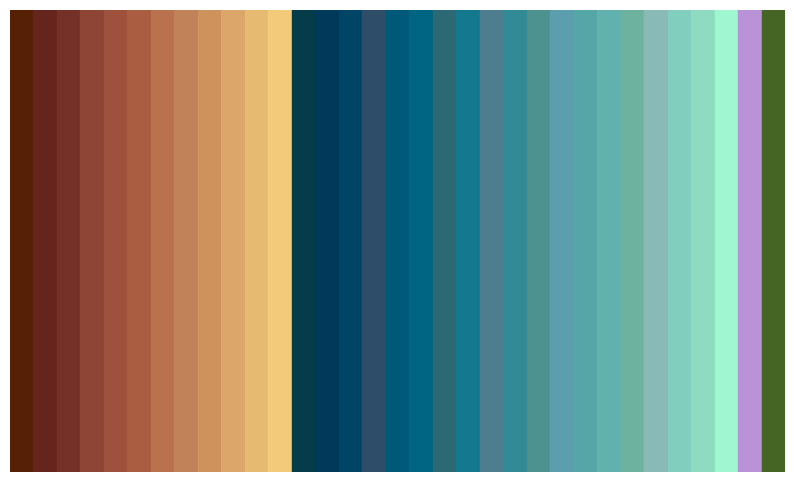

In [13]:
palette = glasbey.create_block_palette(block_shape,lightness_bounds=(15, 90),
        chroma_bounds=(0, 40), optimize_palette=True)
show_palette(palette)

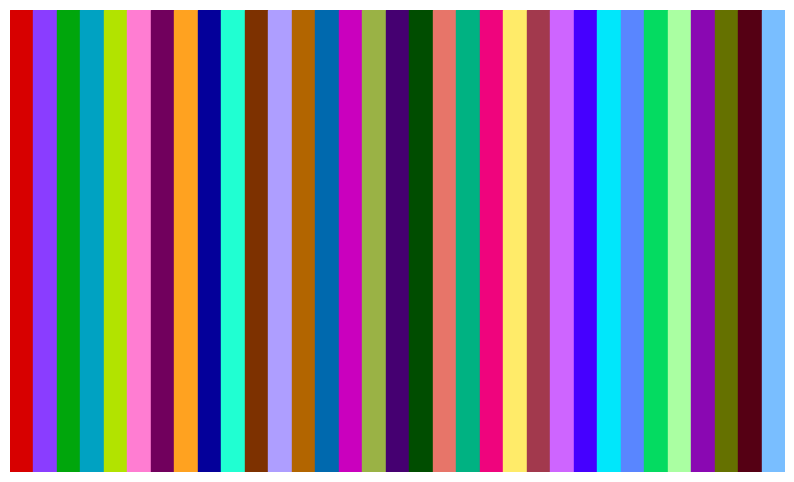

In [14]:
palette = glasbey.create_palette(palette_size=len(aml) + len(ball) + 2,
                                 chroma_bounds=(50, 100),
                                 optimize_palette=True)

show_palette(palette)


In [15]:
# Map each color in palette to a class in aml and ball
pal_dict = {}
for i, cls in enumerate(aml):
    pal_dict[cls] = palette[i]
for i, cls in enumerate(ball):
    pal_dict[cls] = palette[i + len(aml)]
pal_dict["T-ALL"] = palette[-2]
pal_dict["Non-leukemic"] = palette[-1]
pal_dict

{np.str_('AML, APL-PML::RARA'): '#d70000',
 np.str_('AML, CBFA2T3::GLIS2'): '#8a3dff',
 np.str_('AML, CBFB::MYH11'): '#00a60c',
 np.str_('AML, CEBPAalt'): '#00a2c2',
 np.str_('AML, DEK::NUP214'): '#b2e300',
 np.str_('AML, ETV6-r'): '#ff7dd2',
 np.str_('AML, KMT2A-r'): '#71005d',
 np.str_('AML, NPM1alt'): '#ffa220',
 np.str_('AML, NUP98-r'): '#04009a',
 np.str_('AML, PICALM::MLLT10'): '#20ffd2',
 np.str_('AML, RUNX1::RUNX1T1'): '#7d3100',
 np.str_('AML, other'): '#ae9eff',
 np.str_('B-ALL, BCR::ABL1'): '#b26500',
 np.str_('B-ALL, BCR::ABL1-like'): '#0069ae',
 np.str_('B-ALL, DUX4-r'): '#ca00be',
 np.str_('B-ALL, ETV6::RUNX1'): '#9ab245',
 np.str_('B-ALL, ETV6::RUNX1-like'): '#450071',
 np.str_('B-ALL, HLF-r'): '#004d00',
 np.str_('B-ALL, IKZF1 N159Y'): '#e77569',
 np.str_('B-ALL, KMT2A-r'): '#00b282',
 np.str_('B-ALL, MEF2D-r'): '#ef047d',
 np.str_('B-ALL, MYC-r'): '#ffeb69',
 np.str_('B-ALL, NUTM1-r'): '#a2394d',
 np.str_('B-ALL, PAX5 P80R'): '#ce65ff',
 np.str_('B-ALL, PAX5alt'): '#45

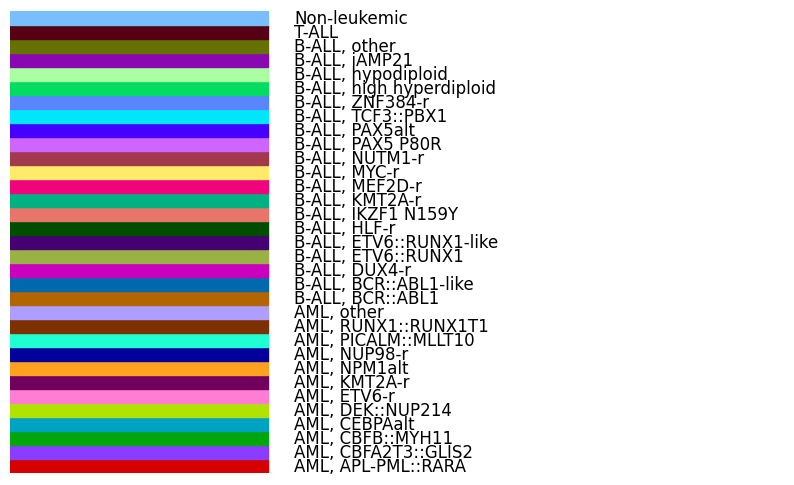

In [16]:
# Visualize pal_dict colors with labels
fig, ax = plt.subplots(figsize=(10, 6))
for i, (cls, color) in enumerate(pal_dict.items()):
    ax.add_patch(Rectangle((0, i), 1, 1, color=color))
    ax.text(1.1, i + 0.5, cls, va='center', fontsize=12)
ax.set_xlim(0, 3)
ax.set_ylim(0, len(pal_dict))
ax.axis('off')
plt.show()


In [19]:
# Save palette as a TSV file without header
pal_df = pd.DataFrame.from_dict(pal_dict, orient='index', columns=['color'])
pal_df.index.name = 'class'
pal_df.to_csv(color_palette_tsv_path, sep='\t', header=False)